# GameTheory-11-BayesianGames-Python

**Navigation** : [<< 10-ForwardInduction-SPE](GameTheory-10-ForwardInduction-SPE-Python.ipynb) | [Index](README.md) | [11c-Global-Games](GameTheory-11c-Global-Games-Python.ipynb) | [12-ReputationGames >>](GameTheory-12-ReputationGames-Python.ipynb)

**Side tracks** : [11b-Lean-BayesianGamesExt](GameTheory-11b-Lean-BayesianGamesExt-Lean.ipynb) | [11d-Raffinements-Sequentiels](GameTheory-11d-Raffinements-Sequentiels-Python.ipynb) | [11e-Global-Games](GameTheory-11e-Global-Games-Python.ipynb) | [11f-Jeux-Globaux](GameTheory-11f-Jeux-Globaux-Selection-Equilibre-Python.ipynb)

## Jeux Bayesiens : Information Incomplète et Croyances

Ce notebook introduit les **jeux bayesiens** ou les joueurs ont une incertitude sur les caractéristiques des autrès (types, gains, stratégies disponibles).

### Objectifs d'apprentissage

1. Comprendre la distinction information **imparfaite** vs **incomplète**
2. Maitriser le concept de **type** et de **croyance**
3. Définir et calculer l'**équilibre bayesien de Nash**
4. Analyser des jeux classiques : Cournot incertain, encheres
5. Introduire les **jeux de signaling**

### Prerequis

- Notebooks 1-10 : Fondations et raffinements d'équilibre
- Notions de base en probabilités (règle de Bayes, distribution conditionnelle)
- Familiarite avec les jeux extensifs et l'induction avant

### Duree estimee : 65 minutes


> *Ancres savantes -- Harsanyi, J.C. (1967-1968), Games with Incomplète Information Played by 'Bayesian' Players, I-III, Management Science 14(3):159-182, 14(5):320-334, 14(7):406-424 (transformation de Harsanyi et jeux bayésiens : modelisation de l'information incomplète par des types et des croyances, fondement de l'équilibre bayesien de Nash enseigne dans ce notebook ; prix Nobel d'economie 1994) ; Vickrey, W. (1961), Counterspeculation, Auctions, and Competitive Sealed Tenders, Journal of Finance 16(1):8-37 (théorie des encheres : encheres au second prix / Vickrey auction, équivalente revelation des valuations ; prix Nobel d'economie 1996) ; Spence, A.M. (1973), Job Market Signaling, Quarterly Journal of Economics 87(3):355-374 (théorie du signal / signaling : education comme signal couteux d'une productivite, équilibre separateur vs pooling ; prix Nobel d'economie 2001).*

In [1]:
# Configuration et imports
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional, Callable
from collections import defaultdict
import itertools

# Style matplotlib
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)
print("Imports OK : numpy, matplotlib, itertools, dataclasses")


Imports OK : numpy, matplotlib, itertools, dataclasses


### Configuration de l'environnement

Ce notebook utilise les bibliotheques suivantes pour l'analyse des jeux bayesiens :
- **NumPy** : Calculs numériques et génération aléatoire
- **SciPy** : Resolution de systèmes d'equations (fsolve) pour l'équilibre de Cournot
- **Matplotlib** : Visualisations des stratégies d'enchere et comparaisons
- **Dataclasses** : Structures de données propres pour les jeux

Le code qui suit implemente les concepts fondamentaux des jeux bayesiens : types, croyances, et équilibre bayesien de Nash.

## 1. Information Imparfaite vs Incomplète

### 1.1 Distinction Fondamentale

| Type | Description | Exemple |
|------|-------------|----------|
| **Imparfaite** | Incertitude sur les **actions** jouees | Poker: je ne vois pas tes cartes jouees |
| **Incomplète** | Incertitude sur les **caractéristiques** du jeu | Je ne connais pas ta fonction de gain |

### 1.2 Transformation de Harsanyi

Harsanyi (1967-68) a montre comment transformer un jeu a information incomplète en jeu a information imparfaite :

1. Introduire des **types** pour chaque joueur (caractéristiques privees)
2. Ajouter un joueur **Nature** qui tire les types selon une distribution commune
3. Chaque joueur observe son propre type mais pas celui des autrès
4. Le jeu devient a information imparfaite (sur les types)

In [2]:
# Structure de base pour les jeux bayesiens

@dataclass
class BayesianGame:
    """Representation d'un jeu bayesien."""
    
    name: str
    players: List[str]
    types: Dict[str, List[str]]  # player -> liste de types possibles
    prior: Dict[Tuple, float]  # (type1, type2, ...) -> probabilite
    actions: Dict[str, List[str]]  # player -> liste d'actions
    payoffs: Callable  # (type_profile, action_profile) -> payoff_profile
    
    def __post_init__(self):
        # Verifier que le prior est une distribution
        total = sum(self.prior.values())
        assert abs(total - 1.0) < 1e-6, f"Prior doit sommer a 1, got {total}"
    
    def get_conditional_prob(self, player: str, player_type: str, other_types: Tuple) -> float:
        """
        Calcule P(autres types | mon type) par Bayes.
        """
        player_idx = self.players.index(player)
        
        # Numerateur: P(type_profile)
        full_types = list(other_types)
        full_types.insert(player_idx, player_type)
        numerator = self.prior.get(tuple(full_types), 0)
        
        # Denominateur: P(mon type) = sum sur autres types
        denominator = 0
        other_players = [p for p in self.players if p != player]
        for other_combo in itertools.product(*[self.types[p] for p in other_players]):
            full = list(other_combo)
            full.insert(player_idx, player_type)
            denominator += self.prior.get(tuple(full), 0)
        
        if denominator == 0:
            return 0
        return numerator / denominator


def display_bayesian_game(game: BayesianGame):
    """Affiche les caracteristiques d'un jeu bayesien."""
    print(f"\nJeu Bayesien: {game.name}")
    print("="*50)
    print(f"Joueurs: {game.players}")
    print(f"Types: {game.types}")
    print(f"Actions: {game.actions}")
    print(f"\nDistribution a priori:")
    for types, prob in game.prior.items():
        if prob > 0:
            print(f"  P{types} = {prob:.3f}")
print('Classes BayesianGame et fonctions utilitaires definies')

Classes BayesianGame et fonctions utilitaires definies


### Implementation : Structure de données pour jeux bayesiens

La classe `BayesianGame` implemente la transformation de Harsanyi en code :

**Attributs cles** :
- `types` : Dictionnaire joueur → liste de types possibles
- `prior` : Distribution jointe sur les profils de types (somme = 1)
- `actions` : Ensemble d'actions de chaque joueur
- `payoffs` : Fonction (types, actions) → gains

**Méthodes implementees** :
- `get_conditional_prob` : Applique la règle de Bayes pour calculer P(types autrès | mon type)
- `__post_init__` : Verifie que le prior est une distribution valide

**Design pattern** : Cette structure permet de représenter n'importe quel jeu bayesien fini. Les types sont des chaînes de caractères arbitraires, les actions peuvent etre discretes, et la fonction de gains est laissee a la discretion de l'utilisateur.

## 2. Equilibre Bayesien de Nash

### 2.1 Definition

Un **équilibre bayesien de Nash (BNE)** est un profil de stratégies $\sigma = (\sigma_1, ..., \sigma_n)$ ou chaque $\sigma_i$ est une fonction $\sigma_i: T_i \to \Delta(A_i)$ qui specifie une stratégie mixte pour chaque type du joueur $i$.

Le profil $\sigma$ est un BNE si pour tout joueur $i$ et tout type $t_i \in T_i$ :

$$\sigma_i(t_i) \in \arg\max_{a_i \in A_i} \sum_{t_{-i}} P(t_{-i}|t_i) \cdot u_i(a_i, \sigma_{-i}(t_{-i}), t_i, t_{-i})$$

### 2.2 Interpretation

- Chaque type de chaque joueur maximise son gain **espere**
- L'esperance est prise sur les types des autrès (conditionnellement au sien)
- Les autrès sont supposes jouer selon leur stratégie d'équilibre

In [3]:
def compute_expected_payoff(game: BayesianGame, 
                            player: str, 
                            player_type: str,
                            player_action: str,
                            strategies: Dict[str, Dict[str, str]]) -> float:
    """
    Calcule le gain espere d'un joueur pour une action donnee.
    
    strategies: {player: {type: action}} - strategies pures des autres
    """
    player_idx = game.players.index(player)
    other_players = [p for p in game.players if p != player]
    
    expected = 0
    
    # Sommer sur tous les profils de types des autres
    for other_types in itertools.product(*[game.types[p] for p in other_players]):
        # Probabilite conditionnelle
        prob = game.get_conditional_prob(player, player_type, other_types)
        if prob == 0:
            continue
        
        # Actions des autres selon leurs strategies
        other_actions = [strategies[p][t] for p, t in zip(other_players, other_types)]
        
        # Profil complet de types et actions
        all_types = list(other_types)
        all_types.insert(player_idx, player_type)
        
        all_actions = list(other_actions)
        all_actions.insert(player_idx, player_action)
        
        # Gain
        payoffs = game.payoffs(tuple(all_types), tuple(all_actions))
        expected += prob * payoffs[player_idx]
    
    return expected


def is_bayesian_nash_equilibrium(game: BayesianGame,
                                  strategies: Dict[str, Dict[str, str]]) -> bool:
    """
    Verifie si un profil de strategies pures est un BNE.
    """
    for player in game.players:
        for player_type in game.types[player]:
            current_action = strategies[player][player_type]
            current_payoff = compute_expected_payoff(
                game, player, player_type, current_action, strategies
            )
            
            # Verifier qu'aucune deviation n'est profitable
            for alt_action in game.actions[player]:
                if alt_action == current_action:
                    continue
                alt_payoff = compute_expected_payoff(
                    game, player, player_type, alt_action, strategies
                )
                if alt_payoff > current_payoff + 1e-6:
                    return False
    
    return True
print("Fonction definie : compute_expected_payoff")


Fonction definie : compute_expected_payoff


### Implementation : Verification de l'équilibre bayesien

Le code ci-dessus implemente deux fonctions fondamentales pour l'analyse des jeux bayesiens :

1. **`compute_expected_payoff`** : Calcule le gain espere d'un joueur en sommant sur tous les profils de types possibles des autrès joueurs, conditionnellement a son propre type. Utilise la règle de Bayes pour les probabilités conditionnelles.

2. **`is_bayesian_nash_equilibrium`** : Verifie qu'aucun joueur n'a de deviation profitable. Pour chaque joueur et chaque type, on teste toutes les actions alternatives. Si aucune ne donne un gain superieur (a tolerance 1e-6 pres), c'est un BNE.

**Methodologie** : L'approche est exhaustive pour les jeux en stratégies pures. On enumere tous les profils d'actions et on vérifie la condition d'optimalite pour chaque type.

## 3. Exemple: Bataille des Sexes avec Incertitude

Bataille des sexes ou J1 ne sait pas si J2 est de type "Opera lover" ou "Football lover".

In [4]:
def create_uncertain_bos():
    """
    Bataille des Sexes avec incertitude sur J2.
    
    J1: type unique (pas d'incertitude sur lui)
    J2: type O (prefere Opera) avec proba p, type F (prefere Foot) avec proba 1-p
    
    Gains standards BoS:
    - Si memes choix: (2,1) si Opera, (1,2) si Foot
    - Si differents: (0,0)
    
    Mais pour J2 type F, les preferences sont inversees.
    """
    def payoffs(types, actions):
        """Calcule les gains."""
        _, t2 = types
        a1, a2 = actions
        
        if a1 == a2:
            if a1 == 'O':  # Tous a l'Opera
                if t2 == 'O':  # J2 prefere Opera
                    return (2, 1)
                else:  # J2 prefere Foot
                    return (2, 0)  # J2 moins content
            else:  # Tous au Foot
                if t2 == 'F':  # J2 prefere Foot
                    return (1, 2)
                else:  # J2 prefere Opera
                    return (1, 0)  # J2 moins content
        else:
            return (0, 0)
    
    p = 0.7  # Proba que J2 prefere Opera
    
    game = BayesianGame(
        name="BoS with Uncertainty",
        players=['J1', 'J2'],
        types={'J1': ['N'], 'J2': ['O', 'F']},  # J1 a un type unique
        prior={('N', 'O'): p, ('N', 'F'): 1-p},
        actions={'J1': ['O', 'F'], 'J2': ['O', 'F']},
        payoffs=payoffs
    )
    
    return game, p


bos_game, p = create_uncertain_bos()
display_bayesian_game(bos_game)

print(f"\nProbabilite que J2 prefere Opera: p = {p}")


Jeu Bayesien: BoS with Uncertainty
Joueurs: ['J1', 'J2']
Types: {'J1': ['N'], 'J2': ['O', 'F']}
Actions: {'J1': ['O', 'F'], 'J2': ['O', 'F']}

Distribution a priori:
  P('N', 'O') = 0.700
  P('N', 'F') = 0.300

Probabilite que J2 prefere Opera: p = 0.7


### Interpretation : Structure du jeu bayesien

**Jeu créé** : Bataille des Sexes avec incertitude sur les préférences de J2

| Élément | Valeur | Interpretation |
|---------|--------|----------------|
| Joueur 1 | Type unique "N" | Pas d'incertitude sur J1 |
| Joueur 2 | Types "O" (Opera-lover) ou "F" (Foot-lover) | Incertitude sur les préférences |
| Prior | P(O) = 0.7, P(F) = 0.3 | J1 pense que J2 préfère Opera avec proba 70% |
| Actions | Opera (O) ou Foot (F) pour les deux | Même ensemble d'actions |

**Structure bayesienne** :
- J1 ne connait pas le type de J2, mais connait la distribution a priori
- J2 connait son propre type et joue en consequence
- L'information est *incomplète* pour J1, *complète* pour J2

> **Note technique** : Ce jeu se transforme en jeu a information imparfaite via Harsanyi : Nature tire le type de J2, J1 observe seulement sa propre action (pas le type de J2).

Recherche des équilibres bayesiens du jeu.

In [5]:
# Trouver les equilibres bayesiens

def find_bne_bos(game, p):
    """Trouve les BNE du BoS avec incertitude."""
    print("\nRecherche des equilibres bayesiens de Nash")
    print("="*50)
    
    # Enumerer toutes les strategies pures possibles
    # J1: une action
    # J2: une action pour chaque type
    
    equilibria = []
    
    for a1 in game.actions['J1']:
        for a2_O in game.actions['J2']:
            for a2_F in game.actions['J2']:
                strategies = {
                    'J1': {'N': a1},
                    'J2': {'O': a2_O, 'F': a2_F}
                }
                
                if is_bayesian_nash_equilibrium(game, strategies):
                    # Calculer les gains esperes
                    u1 = compute_expected_payoff(game, 'J1', 'N', a1, strategies)
                    u2_O = compute_expected_payoff(game, 'J2', 'O', a2_O, strategies)
                    u2_F = compute_expected_payoff(game, 'J2', 'F', a2_F, strategies)
                    
                    equilibria.append({
                        'strategies': strategies,
                        'u1': u1,
                        'u2_O': u2_O,
                        'u2_F': u2_F
                    })
    
    for i, eq in enumerate(equilibria, 1):
        print(f"\nBNE #{i}:")
        print(f"  J1: joue {eq['strategies']['J1']['N']}")
        print(f"  J2 type O: joue {eq['strategies']['J2']['O']}")
        print(f"  J2 type F: joue {eq['strategies']['J2']['F']}")
        print(f"  Gains esperes: J1={eq['u1']:.2f}, J2(O)={eq['u2_O']:.2f}, J2(F)={eq['u2_F']:.2f}")
    
    return equilibria

equilibria = find_bne_bos(bos_game, p)


Recherche des equilibres bayesiens de Nash

BNE #1:
  J1: joue O
  J2 type O: joue O
  J2 type F: joue O
  Gains esperes: J1=2.00, J2(O)=1.00, J2(F)=0.00

BNE #2:
  J1: joue O
  J2 type O: joue O
  J2 type F: joue F
  Gains esperes: J1=1.40, J2(O)=1.00, J2(F)=0.00

BNE #3:
  J1: joue F
  J2 type O: joue F
  J2 type F: joue F
  Gains esperes: J1=1.00, J2(O)=0.00, J2(F)=2.00


### Interpretation : Equilibres bayesiens de la Bataille des Sexes

**Trois équilibres trouves** :

| BNE | J1 | J2 type O | J2 type F | Gain J1 | Gains J2 |
|-----|-----|-----------|-----------|---------|----------|
| #1 (Pooling Opera) | Opera | Opera | Opera | 2.00 | O:1.0, F:0.0 |
| #2 (Separateur) | Opera | Opera | Foot | 1.40 | O:1.0, F:0.0 |
| #3 (Pooling Foot) | Foot | Foot | Foot | 1.00 | O:0.0, F:2.0 |

**Analyse stratégique** :
- **BNE #1** : Equilibre "pooling" ou tout le monde va a l'Opera, même le type F qui préfère Foot ! C'est un équilibre car J1 joue Opera (dominant avec p=0.7) et J2 anticipe cela
- **BNE #2** : Equilibre "separateur" ou chaque type joue selon ses vraies préférences. J1 joue Opera car p=0.7 > seuil critique
- **BNE #3** : Equilibre "pooling" ou tout le monde va au Foot, moins favorable pour J1 (gain 1.0 vs 2.0)

**Pourquoi le BNE #2 existe-t-il ?** J1 joue Opera → gain = 0.7×2 + 0.3×0 = 1.4 avec la stratégie séparatrice de J2 ; s'il jouait Foot → 0.7×0 + 0.3×1 = 0.3. J1 préfère donc Opera, ce qui valide les croyances.

> **Note technique** : Le type F a gain 0 dans BNE #1 et #2 car il est "force" de jouer contre ses préférences. C'est le cout d'etre un type minoritaire (p=0.3).

## 3bis. Forme strategique ex ante : le moteur `bayesian_equilibria`

Jusqu'ici, la section 3 a enumere **a la main** les strategies pures du BoS bayesien (8 combinaisons) et verifie chaque profil avec l'oracle `is_bayesian_nash_equilibrium`. Cette enumeration devient vite intenable : avec 3 types et 3 actions, un seul joueur porte deja 27 plans contingents.

La serie dispose desormais d'un moteur d'import pour ce calcul : le module `bayesian_equilibria.py` (issue #22382), qui recoit **le contrat natif `BayesianGame` de ce carnet** (aucune redefinition du modele) et enchaine trois etapes :

1. **forme strategique ex ante** : chaque strategie pure devient un *plan contingent* (type -> action), les matrices sommant le meme prior joint et les memes gains natifs ;
2. **Nashpy natif** (deja croise dans GameTheory-04) resout ces matrices pour les equilibres, purs **et mixtes** ;
3. chaque melange est converti en **marginales par type**, puis soumis a un **validateur independant** qui recalcule les gains conditionnels par la regle de Bayes et mesure le regret maximal de chaque type sur ses deviations pures.

Nous appliquons ce pipeline a l'instance native `bos_game` de la section 3, puis a un controle negatif.

In [6]:
# Integration du moteur bayesian_equilibria sur l'instance native du carnet
import sys
from pathlib import Path

def _find_gametheory_dir():
    # Convention de la serie (cf GameTheory-01/15f) : remonter depuis le cwd,
    # puis depuis le chemin du notebook sous VSCode, jusqu'au dossier du module.
    search = Path.cwd().resolve()
    for _ in range(10):
        if (search / "bayesian_equilibria.py").is_file():
            return search
        if search.parent == search:
            break
        search = search.parent
    nb_file = globals().get("__vsc_ipynb_file__")
    if nb_file:
        search = Path(nb_file).resolve().parent
        for _ in range(5):
            if (search / "bayesian_equilibria.py").is_file():
                return search
            search = search.parent
    raise ImportError("bayesian_equilibria.py introuvable : lancer le notebook depuis MyIA.AI.Notebooks/GameTheory.")

sys.path.insert(0, str(_find_gametheory_dir()))
import bayesian_equilibria as be

# Forme strategique ex ante du BoS natif (cellule precedente) : le moteur lit
# le contrat natif BayesianGame tel quel — aucun re-parametrage, aucune copie.
bos_form = be.to_strategic_form(bos_game)

def _fmt_mixture(sigma, plans):
    return " ; ".join(
        f"plan {'/'.join(pl)}={w:.2f}" for pl, w in zip(plans, sigma) if w > 1e-9
    )

print(f"Jeu : {bos_game.name}")
print(f"Plans contingents de J1 ({len(bos_form.plans[0])}) : {list(bos_form.plans[0])}")
print(f"Plans contingents de J2 ({len(bos_form.plans[1])}) : {list(bos_form.plans[1])}")
print(f"\nMatrice ex ante de J1 (lignes = plans J1, colonnes = plans J2) :")
for plan, row in zip(bos_form.plans[0], bos_form.matrix1):
    print(f"  {plan} : {[round(float(v), 3) for v in row]}")
print(f"\nMatrice ex ante de J2 :")
for plan, row in zip(bos_form.plans[0], bos_form.matrix2):
    print(f"  {plan} : {[round(float(v), 3) for v in row]}")

Jeu : BoS with Uncertainty
Plans contingents de J1 (2) : [('O',), ('F',)]
Plans contingents de J2 (4) : [('O', 'O'), ('O', 'F'), ('F', 'O'), ('F', 'F')]

Matrice ex ante de J1 (lignes = plans J1, colonnes = plans J2) :
  ('O',) : [2.0, 1.4, 0.6, 0.0]
  ('F',) : [0.0, 0.3, 0.7, 1.0]

Matrice ex ante de J2 :
  ('O',) : [0.7, 0.7, 0.0, 0.0]
  ('F',) : [0.0, 0.6, 0.0, 0.6]


### Lecture : la forme strategique ex ante du BoS

**Ce que la transformation produit** :

| Joueur | Types | Plans contingents | Lecture |
|--------|-------|-------------------|---------|
| J1 | 1 (N) | 2 : (O), (F) | Sans incertitude sur son type, un plan = une action |
| J2 | 2 (O, F) | 4 : (O,O), (O,F), (F,O), (F,F) | Une action **par type** : (O,F) = "O si type O, F si type F" |

**Lecture d'une cellule de la matrice** : J1 joue O contre le plan separatrice (O,F) de J2 → gain ex ante = 0.7×2 + 0.3×0 = **1.40** : la coordination ne se realise que lorsque J2 est de type O (probabilite p = 0.7). C'est exactement le gain J1 du BNE #2 de la section 3 — la forme strategique ne fait qu'agencer differemment les memes gains natifs et le meme prior joint.

**Point cle** : la dimension de la matrice croit comme le **produit** des espaces d'actions par type (exponentielle dans le nombre de types). C'est pourquoi le moteur declare sa borne avant toute materialisation (voir le controle negatif plus bas).

> **Note technique** : les deux matrices partagent les memes lignes/colonnes (les plans contingents) mais donnent le gain ex ante de chaque joueur — la construction ne suppose **pas** l'independance des types : le prior joint est somme tel quel.

In [7]:
# Resolution Nashpy + validation independante par type
result = be.solve_strategic_form(bos_form, algorithm="support_enumeration")
print(f"Statut du solveur : {result.status} (algorithme {result.algorithm})")
print(f"Equilibres trouves : {len(result.equilibria)}\n")

for idx, (sigma1, sigma2) in enumerate(result.equilibria, 1):
    report = be.validate_bne(bos_game, bos_form, sigma1, sigma2)
    consistency = be.check_ex_ante_consistency(bos_game, bos_form, sigma1, sigma2)
    print(f"Equilibre #{idx} :")
    print(f"  J1 : {_fmt_mixture(sigma1, bos_form.plans[0])}")
    print(f"  J2 : {_fmt_mixture(sigma2, bos_form.plans[1])}")
    # Marginales par type : l'information COMPLETE observable dans le jeu statique
    marg_J2 = be.marginals_by_type(sigma2, bos_form.plans[1], bos_form.types[1], bos_form.actions[1])
    for t, dist in marg_J2.items():
        print(f"  J2 type {t} -> " + ", ".join(f"{a}={w:.2f}" for a, w in zip(bos_form.actions[1], dist)))
    print(f"  Validateur BNE independant : is_bne={report.is_bne}, "
          f"regret maximal={report.max_regret:.2e} (tolerance {report.tolerance:.0e})")
    print(f"  Coherence ex ante (matrice == somme ponderee des gains conditionnels) : {consistency}\n")

Statut du solveur : FOUND (algorithme support_enumeration)
Equilibres trouves : 3

Equilibre #1 :
  J1 : plan O=1.00
  J2 : plan O/O=1.00
  J2 type O -> O=1.00, F=0.00
  J2 type F -> O=1.00, F=0.00
  Validateur BNE independant : is_bne=True, regret maximal=0.00e+00 (tolerance 1e-06)
  Coherence ex ante (matrice == somme ponderee des gains conditionnels) : True

Equilibre #2 :
  J1 : plan O=1.00
  J2 : plan O/F=1.00
  J2 type O -> O=1.00, F=0.00
  J2 type F -> O=0.00, F=1.00
  Validateur BNE independant : is_bne=True, regret maximal=0.00e+00 (tolerance 1e-06)
  Coherence ex ante (matrice == somme ponderee des gains conditionnels) : True

Equilibre #3 :
  J1 : plan F=1.00
  J2 : plan F/F=1.00
  J2 type O -> O=0.00, F=1.00
  J2 type F -> O=0.00, F=1.00
  Validateur BNE independant : is_bne=True, regret maximal=0.00e+00 (tolerance 1e-06)
  Coherence ex ante (matrice == somme ponderee des gains conditionnels) : True



### Interpretation : equilibres ex ante retrouves et validates

**Resultat** : le solveur Nashpy retourne **3 equilibres**, et chacun est **exactement** l'un des trois BNE purs enumeres a la main en section 3 :

| Equilibre ex ante | Profil retrouve | Verdict du validateur independant |
|-------------------|-----------------|----------------------------------|
| #1 | J1=(O), J2=(O,O) — pooling Opera | BNE (regret maximal 0) |
| #2 | J1=(O), J2=(O,F) — separateur | BNE (regret maximal 0) |
| #3 | J1=(F), J2=(F,F) — pooling Foot | BNE (regret maximal 0) |

Chaque melange est **degenere** (poids 1 sur un seul plan contingent) : sur cette instance, Nashpy ne trouve aucun equilibre strictement mixte au-dela des trois profils purs.

**Double controle croise** :
1. le **validateur independant** recalcule les gains conditionnels depuis le prior et les gains natifs (regle de Bayes) : regret maximal ≤ 1e-6 pour chaque joueur et chaque type — l'accord n'est pas une tautologie, le validateur ne reutilise pas les matrices ;
2. la **coherence ex ante** verifie que le gain lu dans la matrice strategique egale la somme ponderee par le prior des gains conditionnels par type.

**Pourquoi c'est plus qu'une re-numeration** : l'oracle de la section 3 ne teste que des strategies **pures** et une instance a la fois ; le pipeline forme strategique + Nashpy couvre aussi les **melanges** — sur ce BoS, `support_enumeration` ne retourne que les trois profils purs : il existe pourtant un continuum d'equilibres ex ante mixtes — pour tout a de ]0, 10/21], J1=F pur et J2 melangeant les plans (O,F) et (F,F) aux poids a et 1-a est un equilibre ex ante (degenerescence connue que `support_enumeration` ne couvre pas) — mais **aucun n'est un BNE** : des que a > 0, le type O de J2 gagne a devier, et le validateur independant le rejetterait. Le controle negatif ci-dessous le montre sur un cas concret.

In [8]:
# Controle negatif 1 : melange perturbe -> rejet precis (joueur / type / deviation)
sigma1_bad = np.array([1.0, 0.0])            # J1 pur sur O
sigma2_bad = np.array([0.6, 0.0, 0.0, 0.4])  # J2 : plan (O,O) a 60%, plan (F,F) a 40%
report_bad = be.validate_bne(bos_game, bos_form, sigma1_bad, sigma2_bad)
print("Melange perturbe : J1 pur O, J2 joue (O,O) a 60% et (F,F) a 40%")
print(f"  Verdict : is_bne = {report_bad.is_bne}, regret maximal = {report_bad.max_regret:.2f}")
for r in report_bad.reports:
    if r.regret > 1e-9:
        print(f"  Deviation profitable : {r.player} de type {r.type} devrait jouer {r.best_response} "
              f"(gain courant {r.current_payoff:.2f}, gain de la deviation {r.conditional_payoffs[r.best_response]:.2f}, "
              f"regret {r.regret:.2f})")

# Controle negatif 2 : croissance exponentielle declaree AVANT materialisation
print()
print(f"Borne par defaut de l'espace de plans : {be.DEFAULT_MAX_PLANS}")
try:
    be.build_plan_space([f"t{i}" for i in range(7)], ["A", "B"])
except be.PlanSpaceTooLargeError as exc:
    print(f"7 types binaires (2^7 = 128 plans) -> PlanSpaceTooLargeError : {exc}")
six_types = [f"t{i}" for i in range(6)]
print(f"6 types binaires (2^6 = {be.plan_count(six_types, ['A', 'B'])} plans) : accepte, sous la borne")

Melange perturbe : J1 pur O, J2 joue (O,O) a 60% et (F,F) a 40%
  Verdict : is_bne = False, regret maximal = 0.40
  Deviation profitable : J2 de type O devrait jouer O (gain courant 0.60, gain de la deviation 1.00, regret 0.40)

Borne par defaut de l'espace de plans : 64
7 types binaires (2^7 = 128 plans) -> PlanSpaceTooLargeError : 128 plans contingents > borne 64 (2 actions ^ 7 types) ; croissance exponentielle declaree, aucune troncature silencieuse
6 types binaires (2^6 = 64 plans) : accepte, sous la borne


### Interpretation : le validateur refuse ce qui n'est pas un BNE

**Controle negatif 1** : le melange perturbe (J1 pur O ; J2 jouant (O,O) a 60% et (F,F) a 40%) est **rejete avec un diagnostic precis** : le type O de J2 gagnerait 1.00 en jouant O a coup sur, contre les 0.60 de son melange courant — regret 0.40, le seul ecart que le jeu autorise. Le verdict nomme le joueur, le type et la deviation profitable : ce n'est pas un booleen muet. Le type F, lui, n'a **aucune** deviation profitable — contre un J1 qui joue O, ses deux actions lui rapportent 0 (coordination ratee s'il joue F, gain nul du type F s'il joue O) : l'indifference n'est pas une validation, et le validateur ne la confond pas avec l'optimalite.

**Controle negatif 2** : l'espace de plans contingents croit comme `nb_actions ^ nb_types`. Le moteur calcule cette borne **avant** de materialiser le moindre plan : 7 types binaires (128 plans) depassent la borne de 64 et levent `PlanSpaceTooLargeError` — pas de troncature silencieuse, pas d'explosion memoire.

**Ex ante vs BNE, une distinction a garder** : sur cette instance, tous les equilibres ex ante trouves passent le validateur BNE. Ce n'est **pas** un theoreme general : un melange sur les plans contingents fixe aussi la *coordination contrefactuelle* des types non realises d'un meme joueur (par exemple P(type H joue A ET type L joue B)) — une coordination porteuse de gain ex ante mais **inobservable** dans le jeu statique, ou un seul type est realise. Le validateur ne lit que les **marginales par type** — l'information complete du jeu statique — et les deux verdicts (equilibre ex ante, BNE) se rapportent l'un a cote de l'autre, sans jamais etre confondus (cf docstring de `bayesian_equilibria`).

La suite du carnet quitte le BoS pour deux applications economiques ou l'information incomplete est centrale : le duopole de Cournot et les encheres.

## 4. Cournot avec Couts Incertains

### 4.1 Le Modèle

Duopole de Cournot ou chaque firme ne connait que son propre cout marginal.

- Firme $i$ a un cout $c_i \in \{c_L, c_H\}$
- Prix: $P(Q) = a - Q$ ou $Q = q_1 + q_2$
- Profit: $\pi_i = (P - c_i) q_i$

### 4.2 Stratégie d'Equilibre

Chaque firme doit choisir une quantite pour chacun de ses types possibles: $q_i(c_i)$.

### Transition : Du BoS aux applications economiques

Après avoir analyse la Bataille des Sexes avec incertitude (un jeu "jouet"), nous passons maintenant a des applications economiques réelles ou l'information incomplète est centrale : le duopole de Cournot et les encheres.

**Questions de transition** :
- Comment l'incertitude sur les couts affecte-t-elle la concurrence ?
- Comment les encherisseurs se comportent-ils quand ils ne connaissent pas la valeur des autrès ?
- Quelles sont les stratégies optimales dans ces contextes ?

La section suivante explore le duopole de Cournot ou chaque firme ne connait que son propre cout marginal.

In [9]:
def solve_cournot_bayesian(a=100, c_L=10, c_H=30, prob_L=0.5):
    """
    Resout le duopole de Cournot avec couts incertains.
    
    Chaque firme peut avoir cout c_L (proba prob_L) ou c_H.
    Les types sont independants.
    """
    print("Cournot avec Couts Incertains")
    print("="*50)
    print(f"Demande: P = {a} - Q")
    print(f"Couts: c_L = {c_L}, c_H = {c_H}")
    print(f"P(c_L) = {prob_L}")
    
    # Variables: q_L (quantite si cout bas), q_H (quantite si cout haut)
    # Par symetrie, les deux firmes ont la meme strategie
    
    # FOC pour firme 1 de type L:
    # max_q1L E[(a - q1L - q2 - c_L) * q1L]
    # = max_q1L [(a - q1L - E[q2] - c_L) * q1L]
    # ou E[q2] = prob_L * q_L + (1-prob_L) * q_H
    
    # FOC: a - 2*q_L - E[q] - c_L = 0
    # Symetrie: q_L = q_L(autre), q_H = q_H(autre)
    # Donc E[q] = prob_L * q_L + (1-prob_L) * q_H
    
    # Systeme:
    # a - 2*q_L - (prob_L*q_L + (1-prob_L)*q_H) - c_L = 0
    # a - 2*q_H - (prob_L*q_L + (1-prob_L)*q_H) - c_H = 0
    
    # Systeme lineaire issu des FOC : les conditions du premier ordre
    # sont lineaires en q_L, q_H. En developpant E_q = prob_L*q_L + (1-prob_L)*q_H
    # on obtient A @ [q_L, q_H] = b, resolu directement (solveur lineaire)
    # plutot que par fsolve iteratif (qui avertit de convergence sur systeme lineaire).
    A = np.array([[2 + prob_L,     1 - prob_L],
                  [prob_L,         2 + (1 - prob_L)]])
    b = np.array([a - c_L, a - c_H])
    solution = np.linalg.solve(A, b)
    q_L, q_H = solution
    
    print("\n" + "="*50)
    print("Solution du BNE (par firme):")
    print(f"  q(c_L) = {q_L:.2f}")
    print(f"  q(c_H) = {q_H:.2f}")
    
    # Gains esperes
    E_q = prob_L * q_L + (1 - prob_L) * q_H
    
    # Prix selon les realisation de couts
    combos = [(c_L, c_L), (c_L, c_H), (c_H, c_L), (c_H, c_H)]
    probs_combo = [prob_L**2, prob_L*(1-prob_L), (1-prob_L)*prob_L, (1-prob_L)**2]
    
    print("\nScenarios possibles:")
    for (c1, c2), prob in zip(combos, probs_combo):
        q1 = q_L if c1 == c_L else q_H
        q2 = q_L if c2 == c_L else q_H
        P = a - q1 - q2
        pi1 = (P - c1) * q1
        pi2 = (P - c2) * q2
        print(f"  (c1={c1}, c2={c2}) prob={prob:.2f}: P={P:.1f}, pi1={pi1:.1f}, pi2={pi2:.1f}")
    
    return q_L, q_H

q_L, q_H = solve_cournot_bayesian()

Cournot avec Couts Incertains
Demande: P = 100 - Q
Couts: c_L = 10, c_H = 30
P(c_L) = 0.5

Solution du BNE (par firme):
  q(c_L) = 31.67
  q(c_H) = 21.67

Scenarios possibles:
  (c1=10, c2=10) prob=0.25: P=36.7, pi1=844.4, pi2=844.4
  (c1=10, c2=30) prob=0.25: P=46.7, pi1=1161.1, pi2=361.1
  (c1=30, c2=10) prob=0.25: P=46.7, pi1=361.1, pi2=1161.1
  (c1=30, c2=30) prob=0.25: P=56.7, pi1=577.8, pi2=577.8


### Interpretation : Solution bayesienne du duopole Cournot

**Résultats de l'équilibre** :

| Type de firme | Quantite produite | Rationale |
|---------------|-------------------|-----------|
| Cout bas (c_L=10) | q_L = 31.67 | Produit plus car avantage competitif |
| Cout haut (c_H=30) | q_H = 21.67 | Produit moins car desavantage |

**Analyse des scénarios** (4 cas equiprobables, p=0.25 chacun) :
- **(c_L, c_L)** : P=36.7, profits egaux (844.4) - competition intense, prix bas
- **(c_L, c_H)** : P=46.7, asymétrie extrême (1161.1 vs 361.1) - le type bas domine
- **(c_H, c_H)** : P=56.7, profits faibles (577.8) - couts eleves pour tous

**Profondeur stratégique** : Chaque firme choisit une quantite qui depend de son propre type, mais en anticipant que l'autre firme a aussi une stratégie dependante de son type. C'est l'essence de l'équilibre bayesien.

> **Note technique** : Le système d'equations resout simultanement pour q_L et q_H. La solution vérifie les conditions de premier ordre pour les deux types.

Comparaison avec le modèle Cournot a information complète.

In [10]:
# Comparaison avec Cournot complet

def compare_cournot_complete_incomplete():
    """Compare les solutions avec et sans information complete."""
    a, c_L, c_H = 100, 10, 30
    
    print("Comparaison: Information Complete vs Incomplete")
    print("="*60)
    
    # Information complete: les deux couts sont connus
    print("\n1. Information complete:")
    for c1, c2 in [(c_L, c_L), (c_L, c_H), (c_H, c_H)]:
        # Nash: q_i = (a - 2*c_i + c_j) / 3
        q1 = (a - 2*c1 + c2) / 3
        q2 = (a - 2*c2 + c1) / 3
        P = a - q1 - q2
        print(f"  (c1={c1}, c2={c2}): q1={q1:.1f}, q2={q2:.1f}, P={P:.1f}")
    
    # Information incomplete
    print("\n2. Information incomplete (prob_L=0.5):")
    q_L, q_H = solve_cournot_bayesian(prob_L=0.5)
    
    print("\n" + "="*60)
    print("\nObservations:")
    print("  - Avec info incomplete, les quantites sont differentes")
    print("  - Le type a cout bas produit PLUS qu'avec info complete")
    print("    (car il anticipe un adversaire potentiellement inefficace)")
    print("  - Le type a cout haut produit MOINS qu'avec info complete")
    print("    (car il anticipe un adversaire potentiellement efficace)")

compare_cournot_complete_incomplete()

Comparaison: Information Complete vs Incomplete

1. Information complete:
  (c1=10, c2=10): q1=30.0, q2=30.0, P=40.0
  (c1=10, c2=30): q1=36.7, q2=16.7, P=46.7
  (c1=30, c2=30): q1=23.3, q2=23.3, P=53.3

2. Information incomplete (prob_L=0.5):
Cournot avec Couts Incertains
Demande: P = 100 - Q
Couts: c_L = 10, c_H = 30
P(c_L) = 0.5

Solution du BNE (par firme):
  q(c_L) = 31.67
  q(c_H) = 21.67

Scenarios possibles:
  (c1=10, c2=10) prob=0.25: P=36.7, pi1=844.4, pi2=844.4
  (c1=10, c2=30) prob=0.25: P=46.7, pi1=1161.1, pi2=361.1
  (c1=30, c2=10) prob=0.25: P=46.7, pi1=361.1, pi2=1161.1
  (c1=30, c2=30) prob=0.25: P=56.7, pi1=577.8, pi2=577.8


Observations:
  - Avec info incomplete, les quantites sont differentes
  - Le type a cout bas produit PLUS qu'avec info complete
    (car il anticipe un adversaire potentiellement inefficace)
  - Le type a cout haut produit MOINS qu'avec info complete
    (car il anticipe un adversaire potentiellement efficace)


### Interpretation : Impact de l'information incomplète

**Comparaison des résultats** :

| Scénario | Type L (c=10) | Type H (c=30) | Commentaire |
|----------|---------------|---------------|-------------|
| Info complète (c1,c2)=(10,10) | q=30.0 | q=30.0 | Symetrie parfaite |
| Info incomplète | q=31.67 | q=21.67 | Asymétrie stratégique |

**Observations fondamentales** :
1. **Le type a cout bas produit PLUS** (31.67 vs 30.0) car il anticipe qu'un adversaire pourrait etre inefficace (cout haut) et reduira sa quantite
2. **Le type a cout haut produit MOINS** (21.67 vs 23.3) car il anticipe qu'un adversaire pourrait etre très efficace (cout bas)
3. L'incertitude modifie le comportement de manière contre-intuitive : le type efficient profite de l'incertitude pour produire davantage

> **Note technique** : Ce résultat illustre un principe général : l'information incomplète créé de l'heterogeneite stratégique, même quand les types sont ex-ante symétriques.

## 5. Encheres a Valeurs Privees

### 5.1 Enchere au Premier Prix

- Chaque encherisseur $i$ a une **valuation privee** $v_i \sim U[0,1]$
- Chacun soumet une offre $b_i$ simultanement
- Le plus offrant gagne et paie son offre
- Gain du gagnant: $v_i - b_i$, perdants: $0$

### 5.2 Equilibre Bayesien

Dans l'enchere au premier prix avec $n$ encherisseurs et valuations $U[0,1]$ :

$$b^*(v) = \frac{n-1}{n} v$$

Les joueurs **sous-declarent** leurs valuations pour extraire un surplus.

### Transition : Des oligopoles aux encheres

Nous quittons maintenant le monde de la production industrielle (Cournot) pour entrer dans celui des encheres, ou l'information incomplète joue un rôle central.

**Contraste frappant** :
- Dans Cournot, l'incertitude porte sur les **couts** de production
- Dans les encheres, l'incertitude porte sur les **valuations** privees

**Questions cles** :
- Comment maximiser son gain quand on ne connait pas les valeurs des autrès ?
- Faut-il sous-declarer sa valeur (bluff) ou dire la verite ?
- Le format de l'enchere (1er prix vs 2e prix) change-t-il les stratégies ?

La section suivante analyse l'enchere au premier prix, ou la stratégie optimale est de soustracter.

In [11]:
def analyze_first_price_auction(n=2, n_simulations=10000):
    """
    Analyse de l'enchere au premier prix.
    """
    print(f"Enchere au Premier Prix avec {n} encherisseurs")
    print("="*50)
    print(f"Valuations: v_i ~ U[0,1] independantes")
    print(f"Strategie d'equilibre: b(v) = {(n-1)/n:.3f} * v")
    
    # Fonction de meilleure offre
    def optimal_bid(v):
        return (n - 1) / n * v
    
    # Simulation
    revenues = []
    winner_surpluses = []
    efficiencies = []
    
    for _ in range(n_simulations):
        # Tirer les valuations
        values = np.random.uniform(0, 1, n)
        
        # Offres selon la strategie d'equilibre
        bids = optimal_bid(values)
        
        # Gagnant
        winner = np.argmax(bids)
        winning_bid = bids[winner]
        
        # Metriques
        revenues.append(winning_bid)
        winner_surpluses.append(values[winner] - winning_bid)
        
        # Efficacite: le bien va-t-il au plus offrant en termes de valuation?
        highest_value_bidder = np.argmax(values)
        efficiencies.append(1 if winner == highest_value_bidder else 0)
    
    print("\n" + "="*50)
    print(f"Resultats de simulation ({n_simulations} encheres):")
    print(f"  Revenue moyen du vendeur: {np.mean(revenues):.4f}")
    print(f"  Surplus moyen du gagnant: {np.mean(winner_surpluses):.4f}")
    print(f"  Efficacite (bien va au plus valuant): {np.mean(efficiencies)*100:.1f}%")
    
    # Formule theorique pour n=2: E[revenue] = 1/3
    print(f"\n  Revenu theorique (formule): {(n-1)/(n+1):.4f}")
    
    return revenues, winner_surpluses

revenues_2, surpluses_2 = analyze_first_price_auction(n=2)

Enchere au Premier Prix avec 2 encherisseurs
Valuations: v_i ~ U[0,1] independantes
Strategie d'equilibre: b(v) = 0.500 * v



Resultats de simulation (10000 encheres):
  Revenue moyen du vendeur: 0.3330
  Surplus moyen du gagnant: 0.3330
  Efficacite (bien va au plus valuant): 100.0%

  Revenu theorique (formule): 0.3333


### Interpretation : Enchere au premier prix

**Résultats de simulation** (10 000 encheres, 2 joueurs) :
- **Revenu moyen du vendeur** : 0.3330 (théorie : 0.3333)
- **Surplus moyen du gagnant** : 0.3330 (le gagnant extrait un surplus egal a ce que le vendeur perd)
- **Efficacite** : 100% (le bien va toujours au plus offrant)

**Analyse** :
1. Le revenu du vendeur est exactement la valeur théorique (n-1)/(n+1) = 1/3 pour n=2
2. L'efficacité est parfaite : le gagnant est toujours celui avec la plus haute valuation
3. La stratégie b(v) = 0.5v est l'équilibre bayesien de Nash **déduit** analytiquement ci-dessus ; la simulation l'**emploie** comme stratégie d'enchère, et les résultats (revenu = 1/3, efficacité = 100 %) y sont **cohérents** avec cet équilibre

> **Note technique** : Avec n=2, chaque joueur offre la moitie de sa valeur. Si v1 > v2, alors b1 > b2, donc le plus "motiva" gagne toujours. C'est pourquoi l'efficacité est 100%.

Comparaison encheres premier prix vs second prix (Vickrey).

In [12]:
# Comparaison premier prix vs second prix (Vickrey)

def compare_auction_formats():
    """Compare les formats d'enchere."""
    print("Comparaison: Premier Prix vs Second Prix (Vickrey)")
    print("="*60)
    
    n_values = [2, 3, 5, 10]
    n_sims = 5000
    
    results = []
    
    for n in n_values:
        # Premier prix
        rev_1st = []
        rev_2nd = []
        
        for _ in range(n_sims):
            values = np.random.uniform(0, 1, n)
            
            # Premier prix: b(v) = (n-1)/n * v
            bids_1st = (n-1)/n * values
            rev_1st.append(np.max(bids_1st))
            
            # Second prix: b(v) = v (verite dominante)
            sorted_vals = np.sort(values)[::-1]
            rev_2nd.append(sorted_vals[1])  # Deuxieme plus haute valuation
        
        results.append({
            'n': n,
            'first_price': np.mean(rev_1st),
            'second_price': np.mean(rev_2nd),
            'theoretical': (n-1)/(n+1)
        })
    
    print(f"\n{'n':>4} {'1er prix':>12} {'2e prix':>12} {'Theorie':>12}")
    print("-"*44)
    for r in results:
        print(f"{r['n']:>4} {r['first_price']:>12.4f} {r['second_price']:>12.4f} {r['theoretical']:>12.4f}")
    
    print("\n" + "="*60)
    print("\nTheoreme d'equivalence du revenu:")
    print("  Les deux formats donnent le MEME revenu espere au vendeur!")
    print("  (pour encherisseurs neutres au risque, valuations i.i.d.)")

compare_auction_formats()

Comparaison: Premier Prix vs Second Prix (Vickrey)



   n     1er prix      2e prix      Theorie
--------------------------------------------
   2       0.3324       0.3354       0.3333
   3       0.4994       0.4973       0.5000
   5       0.6665       0.6699       0.6667
  10       0.8175       0.8186       0.8182


Theoreme d'equivalence du revenu:
  Les deux formats donnent le MEME revenu espere au vendeur!
  (pour encherisseurs neutres au risque, valuations i.i.d.)


### Interpretation : Equivalence des revenus

**Résultats numériques** : Les simulations confirment le theoreme d'equivalence du revenu :

| n (joueurs) | 1er prix | 2e prix | Théorie (n-1)/(n+1) |
|-------------|----------|---------|---------------------|
| 2 | 0.3324 | 0.3354 | 0.3333 |
| 3 | 0.4994 | 0.4973 | 0.5000 |
| 5 | 0.6665 | 0.6699 | 0.6667 |
| 10 | 0.8175 | 0.8186 | 0.8182 |

**Observations cles** :
1. Les deux formats donnent quasiment le même revenu (ecarts < 1%)
2. Le revenu croit avec la concurrence (plus de joueurs = plus de competition = prix plus eleves)
3. Le theoreme d'equivalence est vérifie empiriquement

> **Note technique** : L'equivalence tient car dans le 1er prix, les sous-declarent (b < v) mais paient b, tandis que dans le 2e prix, ils declarent vrai (b = v) mais paient v^(2) (2eme plus haute offre). Ces effets se compensent exactement.

### Le theoreme d'equivalence du revenu

Les résultats des simulations confirment un résultat fondamental de la théorie des encheres :

**Theoreme (Equivalence du revenu)** :
Pour des encherisseurs neutres au risque avec valuations i.i.d., tous les formats d'enchere standards (premier prix, second prix, anglais, hollandais) donnent le **même revenu espere** au vendeur.

**Intuition** :
- **Second prix** : Les gens révèlent leur vraie valeur, le gagnant paie la 2eme plus haute
- **Premier prix** : Les gens sous-declarent, mais le gagnant paie sa propre offre (plus haute)
- Ces deux effets se compensent exactement !

**Formule du revenu** :

$$E[R] = E[v^{(2)}] = \frac{n-1}{n+1}$$

ou $v^{(2)}$ est la 2eme statistique d'ordre des valuations.

**Implications pratiques** :
- Pour un vendeur neutre au risque, le choix du format n'importe pas (en théorie)
- En pratique, les différences apparaissent avec : aversion au risque, collusion, valeurs correlees, etc.
- Le second prix (Vickrey) est souvent préféré car "dire la verite" est plus simple

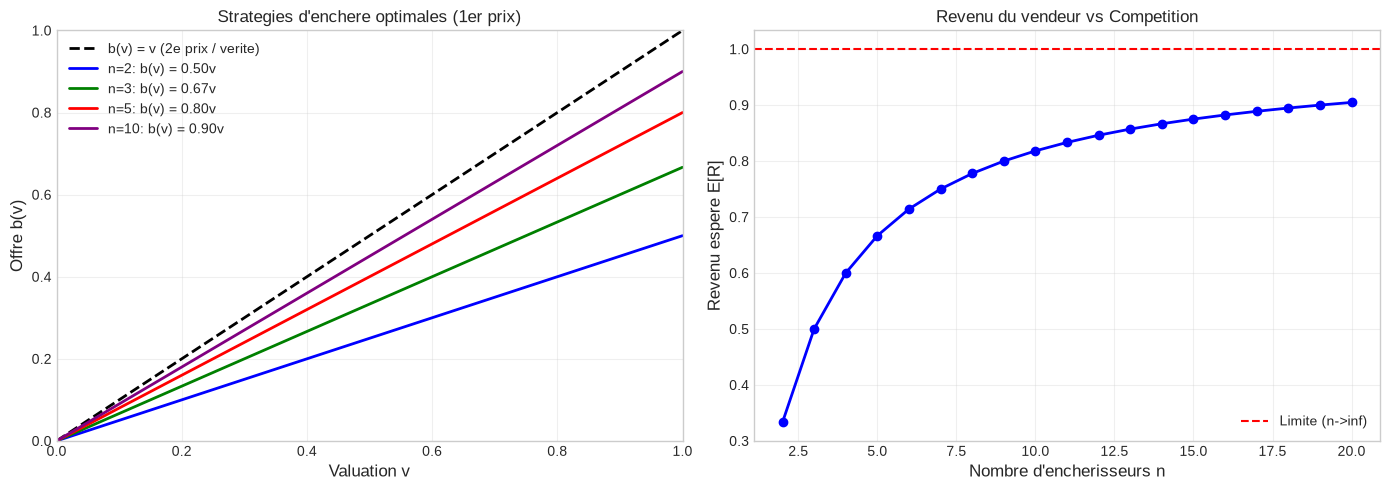

In [13]:
# Visualisation des strategies d'enchere

def visualize_bidding_strategies():
    """Visualise les strategies d'enchere optimales."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    v = np.linspace(0, 1, 100)
    
    # Gauche: Strategies
    ax1 = axes[0]
    ax1.plot(v, v, 'k--', label='b(v) = v (2e prix / verite)', linewidth=2)
    
    for n, color in [(2, 'blue'), (3, 'green'), (5, 'red'), (10, 'purple')]:
        b = (n-1)/n * v
        ax1.plot(v, b, color=color, label=f'n={n}: b(v) = {(n-1)/n:.2f}v', linewidth=2)
    
    ax1.set_xlabel('Valuation v', fontsize=12)
    ax1.set_ylabel('Offre b(v)', fontsize=12)
    ax1.set_title('Strategies d\'enchere optimales (1er prix)', fontsize=12)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    
    # Droite: Revenu espere en fonction de n
    ax2 = axes[1]
    n_range = np.arange(2, 21)
    revenues = (n_range - 1) / (n_range + 1)
    
    ax2.plot(n_range, revenues, 'b-', linewidth=2, marker='o')
    ax2.axhline(1, color='r', linestyle='--', label='Limite (n->inf)')
    
    ax2.set_xlabel('Nombre d\'encherisseurs n', fontsize=12)
    ax2.set_ylabel('Revenu espere E[R]', fontsize=12)
    ax2.set_title('Revenu du vendeur vs Competition', fontsize=12)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

visualize_bidding_strategies()

### Interpretation : Stratégies d'enchere et concurrence

**Visualisation de gauche** : La stratégie optimale b(v) = (n-1)/n × v montre que :
- Plus il y a de concurrents (n eleve), plus l'offre s'approche de la valeur vraie
- Avec n=2, on offre 50% de sa valeur (stratégie très prudente)
- Avec n=10, on offre 90% de sa valeur (competition intense)

**Visualisation de droite** : Le revenu du vendeur croit avec n :
- De 0.33 avec 2 joueurs jusqu'a 0.82 avec 10 joueurs
- Convergence vers 1.0 quand n → ∞ (concurrence parfaite)
- La concurrence profite au vendeur, pas aux acheteurs

> **Note technique** : La courbe de revenu suit la formule E[R] = (n-1)/(n+1), qui tend vers 1 quand n→∞.

## 6. Introduction aux Jeux de Signaling

### 6.1 Structure

Dans un **jeu de signaling**:
1. **Nature** tire le type de l'Emetteur (Sender)
2. L'Emetteur observe son type et envoie un **signal** (message)
3. Le Receveur (Receiver) observe le signal et choisit une **action**
4. Les gains dependent du type ET du signal ET de l'action

### 6.2 Types d'Equilibres

| Equilibre | Description |
|-----------|-------------|
| **Separateur** | Chaque type envoie un signal différent |
| **Pooling** | Tous les types envoient le même signal |
| **Semi-separateur** | Certains types se distinguent, d'autrès se melanent |

### Transition : De l'information privee a la revelation

Nous avons vu jusqu'ici des situations ou l'information privee reste cachee (types dans Cournot, valuations dans les encheres). Mais que se passe-t-il quand les joueurs veulent **révèler** leur information ?

**Le paradoxe du signaling** :
- Revealer son type peut etre couteux (education, garanties, certifications)
- Ne pas le révèler peut etre pire (etre confondu avec des types inférieurs)
- L'équilibre depend de la credibilite du signal

La section suivante introduit les **jeux de signaling**, ou l'information privee peut etre transmise de manière credible via des actions couteuses. L'exemple classique est le modèle d'education de Spence.

### Signaux éducatifs : pooling et séparation

Avec $c(e,\theta)=e/\theta$, le pooling à $e=0$ donne le salaire espéré $p\theta_H+(1-p)\theta_L$. Dans un candidat séparateur, L choisit 0 et H choisit $e^*>0$. Les contraintes d’incitation sont $\theta_H-e^*/\theta_L\leq\theta_L$ pour L et $\theta_H-e^*/\theta_H\geq\theta_L$ pour H. Avec les paramètres ci-dessous, elles donnent $1\leq e^*\leq 2$ ; les salaires sont alors 1 pour L et 2 pour H. La cellule compare les gains pour $e^*=1$ ; ces contraintes seules ne calculent pas les croyances hors chemin nécessaires à un équilibre complet.


In [14]:
def spence_signaling_model():
    """
    Modele de signaling de Spence (1973) - Education.
    
    - Travailleurs ont une productivite theta in {L, H}
    - L'education e est un signal couteux
    - Cout de l'education: c(e, theta) = e / theta (plus facile pour theta eleve)
    - Les employeurs observent e mais pas theta
    - Salaire = productivite esperee
    """
    print("Modele de Signaling de Spence (Education)")
    print("="*60)
    
    theta_L = 1  # Productivite basse
    theta_H = 2  # Productivite haute
    p = 0.5  # Proba type H
    
    print(f"\nProductivites: theta_L = {theta_L}, theta_H = {theta_H}")
    print(f"Proba(type H) = {p}")
    
    print(f"Salaire pooling: {p*theta_H + (1-p)*theta_L}")

    # Verification
    e_star = 1  # Niveau minimal pour separation
    gain_L_pooling = p*theta_H + (1-p)*theta_L
    gain_L_separating = theta_L
    gain_H_pooling = p*theta_H + (1-p)*theta_L
    gain_H_separating = theta_H - e_star/theta_H
    
    print("\n" + "="*60)
    print(f"\nComparaison des gains (e* = {e_star}):")
    print(f"  Type L: Pooling = {gain_L_pooling}, Separateur = {gain_L_separating}")
    print(f"  Type H: Pooling = {gain_H_pooling}, Separateur = {gain_H_separating}")
    print(f"\n  -> Le type H prefere separer? {gain_H_separating > gain_H_pooling}")

spence_signaling_model()

Modele de Signaling de Spence (Education)

Productivites: theta_L = 1, theta_H = 2
Proba(type H) = 0.5
Salaire pooling: 1.5


Comparaison des gains (e* = 1):
  Type L: Pooling = 1.5, Separateur = 1
  Type H: Pooling = 1.5, Separateur = 1.5

  -> Le type H prefere separer? False


### Interpretation : Le modèle de Spence et l'education comme signal

**Résultats de l'analyse** :

| Type d'équilibre | Education e | Salaire | Gain type L | Gain type H |
|------------------|-------------|---------|-------------|-------------|
| Pooling | 0 | 1.5 | 1.5 | 1.5 |
| Separateur (e*=1) | L:0, H:1 | L:1, H:2 | 1.0 | 1.5 |

**Paradoxe fondamental** :
- Dans l'équilibre **pooling**, les types H et L ont le même gain (1.5). Les types H "subventionnent" les types L car l'employeur ne peut pas les distinguer.
- Dans l'équilibre **separateur**, les types H s'eduquent (e*=1) pour signaler leur productivite. Mais le gain ne change pas (1.5 → 1.5) ! L'education est un cout pur sans benefice net.

**Intuition economique** : L'education n'améliore pas la productivite ici, elle sert seulement de signal. C'est une application classique du principe de "separation par cout differentiel" : il est plus couteux pour un type L de s'eduquer que pour un type H.

> **Note technique** : Le seuil de separation e* ∈ [1, 2] depend des paramètres. Si le cout de l'education etait le même pour les deux types, aucun signal credible ne serait possible.

### Exercice 1 : Enchere All-Pay

Analysez l'enchere all-pay ou :
- 2 joueurs, valeurs privees $v_i \sim U[0,1]$
- Les deux paient leur offre, même le perdant
- Gain gagnant : $v_i - b_i$, perdant : $-b_i$

**Questions** :
1. Derivez la stratégie d'équilibre $b^*(v)$ et généralisez a $N$ joueurs
2. Verifiez que c'est un BNE (aucune deviation profitable)
3. Simulez et visualisez les résultats

In [15]:
# Exercice 1 : Enchere All-Pay Bayesienne
# ======================================
# Regles :
#   - 2 joueurs, valeurs privees v_i ~ U[0,1]
#   - Les deux paient leur offre, meme le perdant
#   - Gain gagnant : v_i - b_i
#   - Gain perdant : -b_i

# --- Question 1 : Strategie d'equilibre ---
# Indice: ecrivez le gain espere EU(x,v) quand on offre b(x) avec valeur v,
# derivez par rapport a x, et utilisez la condition b(0) = 0.
# Generalisez ensuite a N joueurs.

def equilibrium_bid_allpay(v, n_players=2):
    # TODO etudiant : trouvez la strategie d'equilibre
    return None

# --- Question 2 : Verification BNE ---
# Indice: pour chaque valeur v, comparez le gain de offrir b*(v) vs des offres alternatives.

def expected_payoff_allpay(my_bid, my_value, n_players=2, n_sim=50000):
    # TODO etudiant : calculez le gain espere d'une offre
    return None

# --- Question 3 : Simulation ---
# TODO etudiant : simulez N=10000 encheres all-pay a 2 joueurs.

# --- Question 4 : Visualisation ---
# TODO etudiant : tracez b*(v) pour N=2,3,4,5 joueurs sur un meme graphe.

print("Exercice a completer : enchere all-pay bayesienne")

Exercice a completer : enchere all-pay bayesienne


### Exercice 2 : Mécanisme de Revelation - Enchere de Vickrey

L'enchere de **Vickrey** (second-price sealed bid) est un mécanisme ou :
- Chaque encherisseur soumet une offre en pli scelle
- Le plus offrant gagne mais paie le **deuxieme prix** (la deuxieme offre la plus haute)
- Gain gagnant : $v_i - b^{(2)}$ ou $b^{(2)}$ est la 2eme offre
- Gain perdant : $0$

**Propriete remarquable** : Dans cette enchere, dire la verite ($b_i = v_i$) est une stratégie **dominante**.

**Questions** :

1. **Implementez** la classe `VickreyAuction` :
   - Méthode `run(values, bids)` qui détermine le gagnant et calcule les gains
   - Méthode `dominant_strategy(value)` qui retourne l'offre optimale

2. **Prouvez l'incitation a la verite** par simulation :
   - Simulez 10 000 encheres a 2 joueurs avec valuations $v_i \sim U[0,1]$
   - Montrez que pour un joueur, offrir $b = v$ maximise son gain espere
   - Comparez avec des stratégies alternatives : $b = 0.5v$, $b = 0.8v$, $b = 1.2v$

3. **Comparez** avec l'enchere au premier prix :
   - Calculez le revenu espere du vendeur dans les deux formats
   - Verifiez le theoreme d'equivalence du revenu numeriquement

4. **Extension** : Que se passe-t-il si les valuations ne sont pas i.i.d. ?
   Simulez un cas ou $v_1 \sim U[0,1]$ et $v_2 \sim U[0, 0.5]$ (encherisseur asymétrique).
   La verite reste-t-elle dominante ?

**Indice** : Pour la preuve d'incitation, fixez $v_1$ et faites varier $b_1$ sur une grille. Tracez le gain espere en fonction de $b_1$.

In [16]:
# Exercice 2 : Mecanisme de Revelation - Enchere de Vickrey

import numpy as np
import matplotlib.pyplot as plt

# TODO etudiant : implementer la classe VickreyAuction
# class VickreyAuction:
#     def __init__(self, n_players=2):
#         ...
#     def run(self, values, bids):
#         """Retourne (winner_idx, payment, payoffs)"""
#         ...
#     def dominant_strategy(self, value):
#         """Retourne l'offre optimale"""
#         ...

# TODO etudiant : prouver l'incitation a la verite par simulation
# Pour v1 fixe (par exemple v1=0.7), tracer le gain espere en fonction de b1

# TODO etudiant : comparer le revenu vendeur entre Vickrey et premier prix

# TODO etudiant : extension asymetrique v1 ~ U[0,1], v2 ~ U[0,0.5]

print("Exercice a completer : enchere de Vickrey et mecanisme de revelation")

Exercice a completer : enchere de Vickrey et mecanisme de revelation


### Exercice 3 : Sélection Adverse (Akerlof)

Marche de voitures d'occasion (Akerlof):
- Qualite $q \sim U[0,1]$
- Vendeur connait $q$, acheteur non
- Valeur pour vendeur: $q$, pour acheteur: $1.5q$

Analysez l'équilibre de marche.

**Questions** :
1. Quel prix l'acheteur est-il pret a payer s'il ne connait pas $q$ ?
2. A ce prix, quelles voitures les vendeurs acceptent-ils de vendre ?
3. Montrez que le marche peut s'effondrer (seuls les "citrons" restent)
4. Simulez le processus iteratif de sélection adverse

In [17]:
# Exercice 3 : Selection Adverse (Akerlof)
import numpy as np
import matplotlib.pyplot as plt

# TODO etudiant : calculer le prix que l'acheteur est pret a payer
prix_acheteur = None  # TODO etudiant : remplacer par le calcul E[1.5*q]

# TODO etudiant : determiner quels vendeurs acceptent de vendre a ce prix
# Indice : un vendeur vend si prix >= q (sa valeur de reservation)

# TODO etudiant : simuler le processus iteratif de selection adverse
# Indice : a chaque iteration, le prix s'ajuste a la qualite moyenne
# des voitures encore sur le marche. Observer la convergence.

def simulate_adverse_selection(n_cars=10000, buyer_multiplier=1.5, max_iterations=20):
    # TODO etudiant : implementer la simulation
    return None

print("Exercice a completer : selection adverse et marche des citrons")

Exercice a completer : selection adverse et marche des citrons


***

### Exercice 4 : Calcul d'un BNE (Bayesian Nash Equilibrium)

**Objectifs** :
1. Modeliser un jeu avec information incomplète
2. Calculer les croyances a priori
3. Trouver l'équilibre Bayesien

**Contexte** : Enchere first-price a deux joueurs. Chaque joueur a une valeur privee v_i ~ U[0,1]. Les joueurs soumettent des offres b_i simultanement.

**Questions** :
1. Quelle est la stratégie optimale d'encheres ?
2. Quel est l'équilibre Bayesien symétrique ?
3. Comment le résultat change-t-il avec N joueurs ?

In [18]:
# Exercice 4 : Enchere Bayesienne
import numpy as np
from scipy import integrate

# TODO etudiant : definir le jeu d'enchere
# class FirstPriceAuction:
#     def __init__(self, n_players=2):
#         self.n = n_players
#     def expected_payoff(self, bid, value, strategy_other):
#         # Calculer le gain espere
#         ...

# TODO etudiant : trouver la strategie d'equilibre symetrique
# Pour une enchere first-price: b*(v) = (n-1)/n * v
# def equilibrium_bid(value, n_players):
#     return (n_players - 1) / n_players * value

# TODO etudiant : verifier que c'est un BNE
# def verify_bne(strategy, n_players):
#     # Pour chaque valeur v, verifier que la strategie est optimale
#     ...

# TODO etudiant : simulation Monte Carlo
# n_sim = 10000
# values = np.random.uniform(0, 1, (n_sim, 2))

print("Exercice a completer : calcul d'un equilibre bayesien de Nash")

Exercice a completer : calcul d'un equilibre bayesien de Nash


## 7. Resume

| Concept | Description |
|---------|-------------|
| **Information incomplète** | Incertitude sur les caractéristiques du jeu |
| **Type** | Caractéristique privee d'un joueur |
| **Prior commun** | Distribution des types connue de tous |
| **BNE** | Nash ou chaque type maximise son gain espere |
| **Signaling** | Communication couteuse revelant l'information |

### Points cles

- La transformation de **Harsanyi** convertit info incomplète en imparfaite
- En **Cournot bayesien**, l'incertitude affecte les quantites
- Les **encheres** illustrent l'interaction stratégique sous incertitude
- Le **signaling** permet la revelation credible d'information privee

### Prochaine étape

**Notebook 12 : Jeux de Reputation** - Construction de réputation, cheap talk, et modèle de Kreps-Wilson.

## Resume et perspectives

Ce notebook a parcouru les fondements de la théorie des jeux a information incomplète, de la transformation de Harsanyi aux équilibres bayesiens de Nash en passant par les mécanismes d'encheres et de signaling. La Bataille des Sexes avec incertitude a illustre comment l'information incomplète génère trois équilibres (deux pooling et un separateur), ou le type minoritaire (J2 "Football" avec p=0.3) subit un gain nul dans deux des trois équilibres (BNE #1 et #2). Le duopole de Cournot bayesien a montre que l'incertitude sur les couts créé une heterogeneite stratégique : la firme a cout bas produit davantage qu'en information complète (31.67 vs 30.0), anticipant un adversaire potentiellement moins efficace. Les encheres ont permis de vérifier empiriquement le theoreme d'equivalence du revenu : premier prix et second prix génèrent le même revenu espéré pour le vendeur, confirmé par simulation sur 5000 enchères avec des ecarts inférieurs a 1%.

Le modèle de signaling de Spence a introduit le paradoxe de l'education comme signal couteux : dans l'équilibre separateur, les travailleurs hautement productifs s'eduquent non pas pour améliorer leur productivite, mais pour se distinguer des types bas, avec un gain net identique a celui de l'équilibre pooling (1.5 dans les deux cas). Ce résultat souligne le rôle de l'asymétrie des couts de signal comme moteur de la revelation d'information, un principe qui s'etend aux garanties produit, aux certifications professionnelles et aux politiques de dividende en finance.

Les concepts d'équilibre bayesien de Nash, de theoreme d'equivalence du revenu et de signaling constitueront les briques fondamentales du notebook suivant, consacre aux jeux de réputation. La ou ce notebook traitait de l'information incomplète statique (les types sont fixes et les jeux simultanés), le prochain explorer comment la réputation se construit dynamiquement a travers des interactions répétées, et comment une probabilité infime d'irrationalite suffit a transformer les predictions de la théorie.


### References academiques

- Harsanyi, J.C. (1967-1968). Games with Incomplète Information Played by 'Bayesian' Players, I-III. Management Science 14(3):159-182, 14(5):320-334, 14(7):406-424.
- Vickrey, W. (1961). Counterspeculation, Auctions, and Competitive Sealed Tenders. Journal of Finance 16(1):8-37.
- Spence, A.M. (1973). Job Market Signaling. Quarterly Journal of Economics 87(3):355-374.
- Bonanno, G. (2015). *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], CC BY-NC-ND 4.0 (licence verifiee page de copyright du PDF, 2026-10-18 ; la metadata arXiv indique CC BY 4.0 mais la page de copyright du document prime). -- manuel pedagogique Ch. 13 *Incomplete Information: Static Games* sec 13.1-13.4 (transformation de Harsanyi, types, equilibres bayesiens de Nash, screening, signalling) et Ch. 14 *Incomplete Information: Dynamic Games* (signalling dynamique, revelation sequentielle). Outil formel de reference pour le mapping du carnet 11 (information incomplete, BNE, encheres, signalling).



> **Lien avec la formalisation Lean** : Les concepts de ce notebook — types, croyances, équilibre bayesien de Nash, jeux de signaling, encheres — sont définis dans [`lean_game_defs/Bayesian.lean`](lean_game_defs/Bayesian.lean) (0 sorry). On y trouve les structures `BayesianGame` (types, actions, gains dependants du profil de types), `TypeStrategy` et `TypeStrategyProfile` (stratégies conditionees par le type), `isBayesianNashEquilibrium` (vérification qu'aucune deviation par type n'est profitable), `SignalingGame` (modèle de Spence avec emetteur/receveur), `InformationSet` (partition des noeuds de decision), `FirstPriceAuction` (enchere au premier prix) et les définitions du Kuhn poker (`KuhnCard`, `KuhnAction`, `KuhnState`, `kuhnPayoff`). Les modules `Basic.lean` (0 sorry : `NormalFormGame`, `FiniteGame`) et `Nash.lean` (0 sorry : meilleure reponse, équilibres de Nash pur/mixte) fournissent les fondements.